In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
CSV_FILES = {
    "syrupUSDC": "../from_dune/morpho_syrup_full_panel.csv",
    "sUSDS":     "../from_dune/morpho_susds_full_panel.csv",
    "sUSDe":     "../from_dune/morpho_aave_susde_full_panel.csv",
}

WALLET_COL = "YBS_wallet_balance"
PROTOCOL_COLS = ["YBS_in_morpho", "YBS_in_aave"]
ADDRESS_COL = "wallet"

PROTOCOL_HEAVY_THRESHOLD = 0.90

In [3]:
dfs = {}
for name, path in CSV_FILES.items():
    df = pd.read_csv(path)
    df["asset"] = name
    dfs[name] = df

all_df = pd.concat(dfs.values(), ignore_index=True)
all_df.shape

(12682, 6)

In [4]:
EPSILON = 1e-3

def classify(row):
    protocol_bal = row["YBS_in_morpho"] + row["YBS_in_aave"]
    total = row["total_YBS_exposure"]

    if total <= 0:
        return "unknown"

    protocol_bal = 0 if abs(protocol_bal) < EPSILON else protocol_bal

    if protocol_bal == 0:
        return "wallet_only"

    protocol_pct = protocol_bal / total

    if protocol_pct > 0.90:
        return "protocol_heavy"

    return "mixed"

all_df["archetype"] = all_df.apply(classify, axis=1)
all_df["archetype"].value_counts()

archetype
wallet_only       11069
protocol_heavy     1479
mixed               134
Name: count, dtype: int64

In [5]:
for name, df in dfs.items():
    df["category"] = df.apply(classify, axis=1)
    print(f"--- {name} ---")
    print(df["category"].value_counts())

--- syrupUSDC ---
category
wallet_only       1924
protocol_heavy      78
mixed                5
Name: count, dtype: int64
--- sUSDS ---
category
wallet_only       3135
protocol_heavy      93
mixed               14
Name: count, dtype: int64
--- sUSDe ---
category
wallet_only       6010
protocol_heavy    1308
mixed              115
Name: count, dtype: int64


In [6]:
summary = (
    all_df
    .groupby(["asset", "archetype"])
    .agg(
        wallets=("wallet", "count"),
        total_exposure=("total_YBS_exposure", "sum"),
    )
    .reset_index()
)

summary["pct_of_wallets"] = (
    summary["wallets"] / summary.groupby("asset")["wallets"].transform("sum") * 100
)
summary["pct_of_exposure"] = (
    summary["total_exposure"] / summary.groupby("asset")["total_exposure"].transform("sum") * 100
)

summary.sort_values(["asset", "total_exposure"], ascending=[True, False])

,asset,archetype,wallets,total_exposure,pct_of_wallets,pct_of_exposure
2,sUSDS,wallet_only,3135,3.943055e+09,96.699568,98.433965
1,sUSDS,protocol_heavy,93,6.144713e+07,2.868600,1.533959
0,sUSDS,mixed,14,1.284881e+06,0.431832,0.032076
5,sUSDe,wallet_only,6010,1.213273e+09,80.855644,57.201653
4,sUSDe,protocol_heavy,1308,8.994248e+08,17.597202,42.404795
3,sUSDe,mixed,115,8.347405e+06,1.547155,0.393552
8,syrupUSDC,wallet_only,1924,1.097373e+09,95.864474,90.208648
7,syrupUSDC,protocol_heavy,78,1.191100e+08,3.886398,9.791337
6,syrupUSDC,mixed,5,1.887814e+02,0.249128,0.000016


In [7]:
def protocol_type(row):
    morpho = 0 if abs(row["YBS_in_morpho"]) < EPSILON else row["YBS_in_morpho"]
    aave = 0 if abs(row["YBS_in_aave"]) < EPSILON else row["YBS_in_aave"]

    if morpho > 0 and aave > 0:
        return "both"
    elif morpho > 0:
        return "morpho"
    elif aave > 0:
        return "aave"
    else:
        return "none"

for name, df in dfs.items():
    df["protocol_type"] = df.apply(protocol_type, axis=1)

In [8]:
colors = {
    "wallet_only":            "#4C72B0",  # blue
    "mixed":                  "#E8A33D",  # amber
    "mixed_morpho":           "#B9752A",  # darker amber
    "mixed_aave":             "#F2C46D",  # lighter amber
    "protocol_heavy":         "#55A868",  # green
    "protocol_heavy_morpho":  "#2E6F4E",  # darker green
    "protocol_heavy_aave":    "#9BCBA8",  # lighter green
}

labels = {
    "wallet_only": "Wallet only",
    "mixed": "Mixed",
    "mixed_morpho": "Mixed (Morpho)",
    "mixed_aave": "Mixed (Aave)",
    "protocol_heavy": "Protocol heavy",
    "protocol_heavy_morpho": "Protocol heavy (Morpho)",
    "protocol_heavy_aave": "Protocol heavy (Aave)",
}

In [9]:
def build_segments(name, df):
    n = len(df)
    if name == "sUSDe":
        segs = {
            "wallet_only":            (df["category"] == "wallet_only").sum(),
            "mixed_morpho":           ((df["category"] == "mixed") & (df["protocol_type"] == "morpho")).sum(),
            "mixed_aave":             ((df["category"] == "mixed") & (df["protocol_type"] == "aave")).sum(),
            "protocol_heavy_morpho":  ((df["category"] == "protocol_heavy") & (df["protocol_type"] == "morpho")).sum(),
            "protocol_heavy_aave":    ((df["category"] == "protocol_heavy") & (df["protocol_type"] == "aave")).sum(),
        }
    else:
        segs = {
            "wallet_only":     (df["category"] == "wallet_only").sum(),
            "mixed":           (df["category"] == "mixed").sum(),
            "protocol_heavy":  (df["category"] == "protocol_heavy").sum(),
        }
    return segs, n

In [10]:
asset_order = ["syrupUSDC", "sUSDe", "sUSDS"]

segment_data = {}
for name in asset_order:
    segs, n = build_segments(name, dfs[name])
    segment_data[name] = {"segs": segs, "n": n}

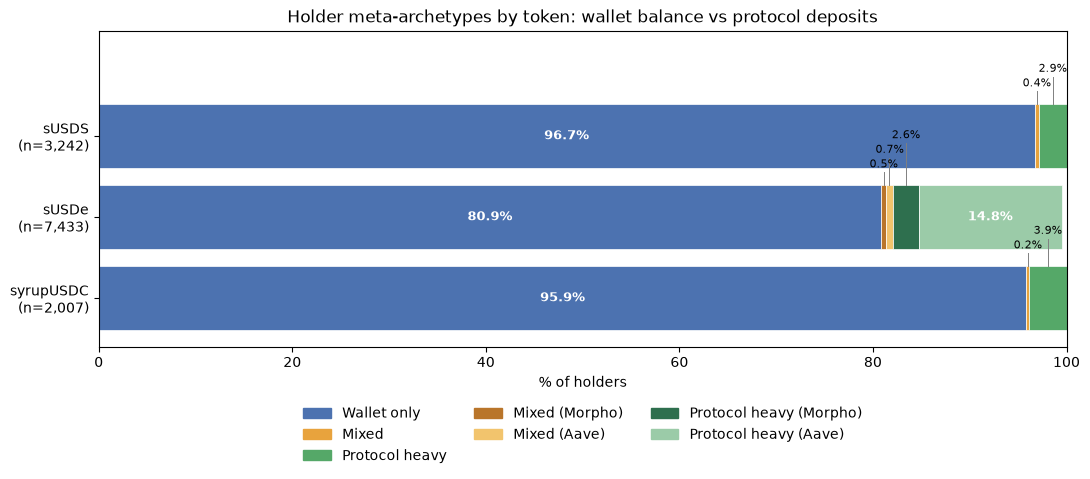

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))

y_positions = range(len(asset_order))

for y, name in zip(y_positions, asset_order):
    segs = segment_data[name]["segs"]
    n = segment_data[name]["n"]
    left = 0
    small_segments = []

    for seg_name, count in segs.items():
        if count == 0:
            continue
        pct = count / n * 100
        ax.barh(y, pct, left=left, color=colors[seg_name], edgecolor="white", linewidth=0.5)

        if pct >= 4:
            ax.text(left + pct / 2, y, f"{pct:.1f}%", ha="center", va="center",
                     color="white", fontweight="bold", fontsize=9)
        else:
            small_segments.append((left + pct / 2, pct))

        left += pct

    for i, (x_center, pct) in enumerate(small_segments):
        y_offset = 0.55 + (i * 0.18)
        ax.plot([x_center, x_center], [y + 0.4, y + y_offset], color="gray", linewidth=0.7)
        ax.text(x_center, y + y_offset + 0.03, f"{pct:.1f}%", ha="center", va="bottom", fontsize=8)

ax.set_yticks(list(y_positions))
ax.set_yticklabels([f"{name}\n(n={segment_data[name]['n']:,})" for name in asset_order])
ax.set_xlabel("% of holders")
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(asset_order) - 0.3 + 0.6)
ax.set_title("Holder meta-archetypes by token: wallet balance vs protocol deposits")

used_segments = []
for name in asset_order:
    for seg_name, count in segment_data[name]["segs"].items():
        if count > 0 and seg_name not in used_segments:
            used_segments.append(seg_name)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[s]) for s in used_segments]
ax.legend(handles, [labels[s] for s in used_segments], loc="upper center",
          bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

plt.tight_layout()
plt.savefig("../output/holder_meta_archetypes.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
def protocol_group(row):
    m = row["YBS_in_morpho"] > 0
    a = row["YBS_in_aave"] > 0
    if m and a:
        return "both"
    elif m:
        return "morpho_only"
    elif a:
        return "aave_only"
    else:
        return "wallet_only"

all_df["protocol_group"] = all_df.apply(protocol_group, axis=1)

split_table = (
    all_df.groupby(["asset", "protocol_group"])
    .agg(
        wallets=("wallet", "count"),
        total_value=("total_YBS_exposure", "sum"),
    )
    .reset_index()
)

split_table["pct_wallets"] = split_table.groupby("asset")["wallets"].transform(lambda x: x / x.sum() * 100)
split_table["pct_value"] = split_table.groupby("asset")["total_value"].transform(lambda x: x / x.sum() * 100)

split_table.sort_values(["asset", "protocol_group"])

,asset,protocol_group,wallets,total_value,pct_wallets,pct_value
0,sUSDS,morpho_only,107,6.273201e+07,3.300432,1.566035
1,sUSDS,wallet_only,3135,3.943055e+09,96.699568,98.433965
2,sUSDe,aave_only,1222,9.357024e+08,16.440199,44.115160
3,sUSDe,both,21,4.390312e+07,0.282524,2.069882
4,sUSDe,morpho_only,223,1.593381e+07,3.000135,0.751224
5,sUSDe,wallet_only,5967,1.125506e+09,80.277142,53.063734
6,syrupUSDC,morpho_only,83,1.191102e+08,4.135526,9.791352
7,syrupUSDC,wallet_only,1924,1.097373e+09,95.864474,90.208648


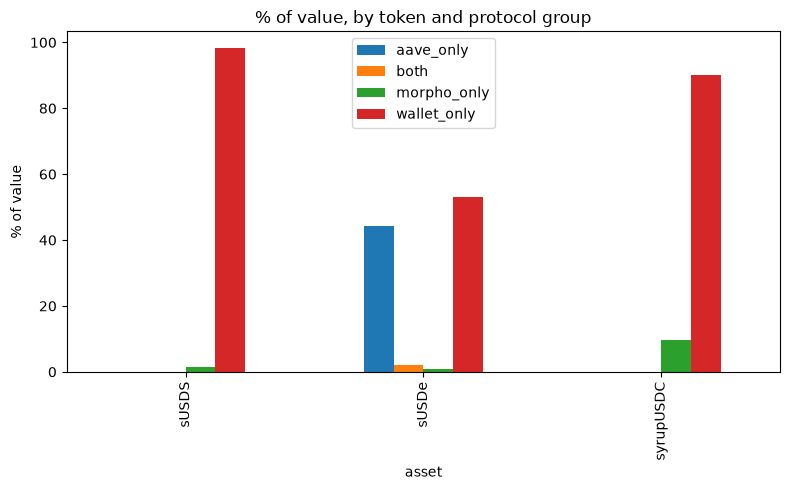

In [13]:

pivot_wallets = split_table.pivot(index="asset", columns="protocol_group", values="pct_wallets").fillna(0)
pivot_value = split_table.pivot(index="asset", columns="protocol_group", values="pct_value").fillna(0)


fig, ax = plt.subplots(figsize=(8, 5))

pivot_value.plot(kind="bar", ax=ax)
ax.set_title("% of value, by token and protocol group")
ax.set_ylabel("% of value")
ax.legend(title="")

plt.tight_layout()
plt.savefig("../output/protocol_split_by_token_value.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
WHALE_THRESHOLD = 1_000_000

all_df["is_whale"] = all_df["total_YBS_exposure"] > WHALE_THRESHOLD

whale_concentration = (
    all_df.groupby(["asset", "is_whale"])
    .agg(
        wallets=("wallet", "count"),
        morpho_value=("YBS_in_morpho", "sum"),
        aave_value=("YBS_in_aave", "sum"),
    )
    .reset_index()
)

whale_concentration["pct_wallets"] = whale_concentration.groupby("asset")["wallets"].transform(lambda x: x / x.sum() * 100)
whale_concentration["pct_morpho_value"] = whale_concentration.groupby("asset")["morpho_value"].transform(
    lambda x: x / x.sum() * 100 if x.sum() > 0 else 0
)
whale_concentration["pct_aave_value"] = whale_concentration.groupby("asset")["aave_value"].transform(
    lambda x: x / x.sum() * 100 if x.sum() > 0 else 0
)

whale_concentration

,asset,is_whale,wallets,morpho_value,aave_value,pct_wallets,pct_morpho_value,pct_aave_value
0,sUSDS,False,3046,1.003041e+07,0.000000e+00,93.954349,16.055877,0.000000
1,sUSDS,True,196,5.244148e+07,0.000000e+00,6.045651,83.944123,0.000000
2,sUSDe,False,7294,5.243877e+06,8.526528e+07,98.129961,11.613909,9.948358
3,sUSDe,True,139,3.990782e+07,7.718136e+08,1.870039,88.386091,90.051642
4,syrupUSDC,False,1952,6.208185e+06,0.000000e+00,97.259591,5.214971,0.000000
5,syrupUSDC,True,55,1.128373e+08,0.000000e+00,2.740409,94.785029,0.000000


In [15]:
morpho_whales = all_df[(all_df["is_whale"]) & (all_df["YBS_in_morpho"] > 0)][
    ["wallet", "asset", "YBS_wallet_balance", "YBS_in_morpho", "total_YBS_exposure"]
]
morpho_whales.to_csv("morpho_whales.csv", index=False)
print("Morpho whales:", len(morpho_whales))

Morpho whales: 41


In [16]:
aave_whales = all_df[(all_df["is_whale"]) & (all_df["YBS_in_aave"] > 0)][
    ["wallet", "asset", "YBS_wallet_balance", "YBS_in_aave", "total_YBS_exposure"]
]
aave_whales.to_csv("aave_whales.csv", index=False)
print("Aave whales:", len(aave_whales))

Aave whales: 81


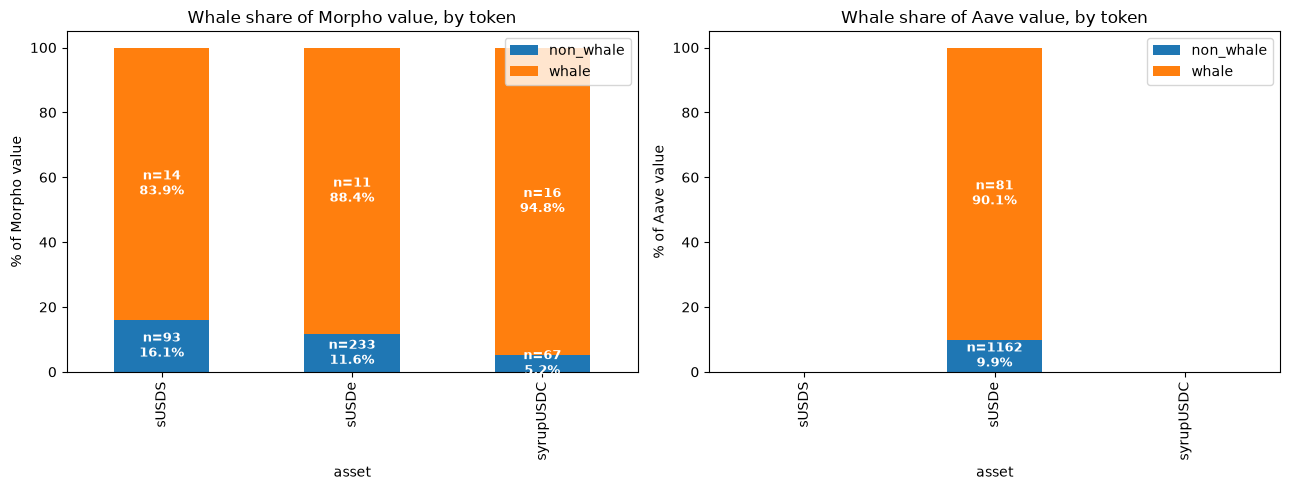

In [17]:
# %% Chart: whale share of Morpho and Aave value, with correctly filtered wallet counts

# wallet counts filtered to only wallets with actual Morpho exposure
morpho_wallets = (
    all_df[all_df["YBS_in_morpho"] > 0]
    .groupby(["asset", "is_whale"])["wallet"].count()
    .reset_index(name="wallets")
)
wallets_pivot_morpho = morpho_wallets.pivot(index="asset", columns="is_whale", values="wallets").fillna(0)
wallets_pivot_morpho.columns = ["non_whale", "whale"]

# wallet counts filtered to only wallets with actual Aave exposure
aave_wallets = (
    all_df[all_df["YBS_in_aave"] > 0]
    .groupby(["asset", "is_whale"])["wallet"].count()
    .reset_index(name="wallets")
)
wallets_pivot_aave = aave_wallets.pivot(index="asset", columns="is_whale", values="wallets").fillna(0)
wallets_pivot_aave.columns = ["non_whale", "whale"]

pivot_morpho = whale_concentration.pivot(index="asset", columns="is_whale", values="pct_morpho_value").fillna(0)
pivot_morpho.columns = ["non_whale", "whale"]

pivot_aave = whale_concentration.pivot(index="asset", columns="is_whale", values="pct_aave_value").fillna(0)
pivot_aave.columns = ["non_whale", "whale"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

pivot_morpho.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Whale share of Morpho value, by token")
axes[0].set_ylabel("% of Morpho value")
axes[0].legend(title="")

pivot_aave.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Whale share of Aave value, by token")
axes[1].set_ylabel("% of Aave value")
axes[1].legend(title="")

for ax, pivot_pct, wallets_pivot_local in [(axes[0], pivot_morpho, wallets_pivot_morpho), (axes[1], pivot_aave, wallets_pivot_aave)]:
    for i, asset in enumerate(pivot_pct.index):
        bottom = 0
        for col in pivot_pct.columns:
            pct = pivot_pct.loc[asset, col]
            count = wallets_pivot_local.loc[asset, col] if asset in wallets_pivot_local.index and col in wallets_pivot_local.columns else 0
            if pct > 0:
                ax.text(i, bottom + pct / 2, f"n={int(count)}\n{pct:.1f}%", ha="center", va="center",
                        color="white", fontweight="bold", fontsize=9)
            bottom += pct

plt.tight_layout()
plt.savefig("../output/whale_concentration_morpho_aave.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# %% Supply, holder counts, and top-holder concentration, per token (with whale count)

WHALE_THRESHOLD = 1_000_000

def concentration_summary(df, name):
    total_supply = df["total_YBS_exposure"].sum()
    holder_count = df["wallet"].nunique()

    sorted_df = df.sort_values("total_YBS_exposure", ascending=False)
    top1_value = sorted_df["total_YBS_exposure"].iloc[0]
    top10_value = sorted_df["total_YBS_exposure"].iloc[:10].sum()

    whale_count = (df["total_YBS_exposure"] > WHALE_THRESHOLD).sum()

    return {
        "token": name,
        "total_supply": total_supply,
        "holder_count": holder_count,
        "top1_value": top1_value,
        "top1_pct_of_supply": 100 * top1_value / total_supply,
        "top10_value": top10_value,
        "top10_pct_of_supply": 100 * top10_value / total_supply,
        "whale_count": whale_count,
    }

concentration_table = pd.DataFrame([concentration_summary(df, name) for name, df in dfs.items()])
concentration_table

,token,total_supply,holder_count,top1_value,top1_pct_of_supply,top10_value,top10_pct_of_supply,whale_count
0,syrupUSDC,1.216483e+09,2007,5.256983e+08,43.214592,1.010619e+09,83.077136,55
1,sUSDS,4.005787e+09,3242,9.126179e+08,22.782487,2.869010e+09,71.621641,196
2,sUSDe,2.121045e+09,7433,4.909108e+08,23.144760,1.326926e+09,62.560013,139


In [19]:
# % of holders that are whales, separately for Morpho and Aave depositors

morpho_depositors = all_df[all_df["YBS_in_morpho"] > 0]
aave_depositors = all_df[all_df["YBS_in_aave"] > 0]

morpho_whale_pct = (
    morpho_depositors.groupby("asset")["is_whale"]
    .mean()  # mean of True/False = % that are True
    .mul(100)
    .rename("pct_whales_morpho")
)

aave_whale_pct = (
    aave_depositors.groupby("asset")["is_whale"]
    .mean()
    .mul(100)
    .rename("pct_whales_aave")
)

whale_pct_table = pd.concat([morpho_whale_pct, aave_whale_pct], axis=1)
print(whale_pct_table)

           pct_whales_morpho  pct_whales_aave
asset                                        
sUSDS              13.084112              NaN
sUSDe               4.508197         6.516492
syrupUSDC          19.277108              NaN


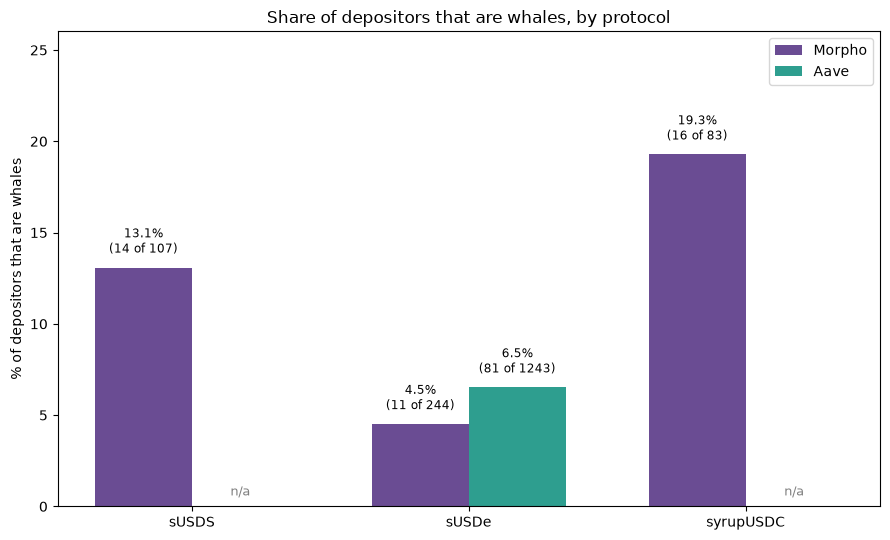

In [26]:
assets = ["sUSDS", "sUSDe", "syrupUSDC"]

# Morpho depositors: rows where YBS_in_morpho > 0
morpho_depositors = all_df[all_df["YBS_in_morpho"] > 0]
morpho_stats = (
    morpho_depositors.groupby("asset")["is_whale"]
    .agg(whales="sum", total="count")
)

# Aave depositors: rows where YBS_in_aave > 0
aave_depositors = all_df[all_df["YBS_in_aave"] > 0]
aave_stats = (
    aave_depositors.groupby("asset")["is_whale"]
    .agg(whales="sum", total="count")
)

morpho_vals, aave_vals = [], []
morpho_labels, aave_labels = [], []

for a in assets:
    if a in morpho_stats.index:
        whales_n = int(morpho_stats.loc[a, "whales"])
        total_n = int(morpho_stats.loc[a, "total"])
        pct = 100 * whales_n / total_n
        morpho_vals.append(pct)
        morpho_labels.append(f"{pct:.1f}%\n({whales_n} of {total_n})")
    else:
        morpho_vals.append(np.nan)
        morpho_labels.append(None)

    if a in aave_stats.index:
        whales_n = int(aave_stats.loc[a, "whales"])
        total_n = int(aave_stats.loc[a, "total"])
        pct = 100 * whales_n / total_n
        aave_vals.append(pct)
        aave_labels.append(f"{pct:.1f}%\n({whales_n} of {total_n})")
    else:
        aave_vals.append(np.nan)
        aave_labels.append(None)

morpho_vals = np.array(morpho_vals)
aave_vals = np.array(aave_vals)

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(assets))
w = 0.35

color_morpho = "#6A4C93"  # purple
color_aave = "#2E9E8F"    # teal

ax.bar(x - w/2, morpho_vals, width=w, color=color_morpho, label="Morpho")
ax.bar(x + w/2, np.nan_to_num(aave_vals), width=w, color=color_aave, label="Aave")

for i in range(len(assets)):
    if not np.isnan(morpho_vals[i]):
        ax.text(x[i] - w/2, morpho_vals[i] + 0.6, morpho_labels[i], ha="center", fontsize=8.5, va="bottom")
    if not np.isnan(aave_vals[i]):
        ax.text(x[i] + w/2, aave_vals[i] + 0.6, aave_labels[i], ha="center", fontsize=8.5, va="bottom")
    else:
        ax.text(x[i] + w/2, 0.6, "n/a", ha="center", fontsize=9, color="gray")

ax.set_xticks(x)
ax.set_xticklabels(assets)
ax.set_ylabel("% of depositors that are whales")
ax.set_title("Share of depositors that are whales, by protocol")
ax.set_ylim(0, np.nanmax(np.concatenate([morpho_vals, aave_vals])) * 1.35)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../output/whale_pct_by_protocol.png", dpi=300, bbox_inches="tight")
plt.show()